# 05.2 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/05-powerful-models/02-random-forest/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

## Exercise 1

$(1 - 1/4)^4 = 0.75^4 = 0.316$. About a third of rows are out of bag even for tiny samples.

In [2]:
rng = np.random.default_rng(0)
samples = rng.integers(0, 4, size=(10_000, 4))
row0_out = ~(samples == 0).any(axis=1)
print(f"formula {0.75**4:.3f}   simulated {row0_out.mean():.3f}")

formula 0.316   simulated 0.314


In [3]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]
cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

def cv_auc(model):
    """Mean 5-fold cross-validated AUC on the training customers."""
    return cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc").mean()

def test_auc(model):
    """Fit on all training customers, score AUC on the held-out test customers."""
    model.fit(X_train, y_train)
    return roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

print(f"Benchmark logistic regression: CV AUC {cv_auc(logreg):.3f}, test AUC {test_auc(logreg):.3f}")

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

Benchmark logistic regression: CV AUC 0.740, test AUC 0.741


## Exercise 2

In [5]:
import time
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=10, oob_score=True, random_state=42, n_jobs=-1)
t0 = time.time(); rf.fit(X_train, y_train); t_oob = time.time() - t0
t0 = time.time(); cv_acc = cross_val_score(rf, X_train, y_train, cv=cv, scoring="accuracy").mean(); t_cv = time.time() - t0
print(f"OOB accuracy {rf.oob_score_:.3f}  ({t_oob:.1f} s, one fit)")
print(f"CV accuracy  {cv_acc:.3f}  ({t_cv:.1f} s, five fits)")

OOB accuracy 0.665  (0.2 s, one fit)
CV accuracy  0.666  (2.1 s, five fits)


They agree to about a point, and OOB costs one fit instead of five. For random forests, OOB is a perfectly good validation estimate during exploration; use proper CV when comparing against non-forest models, so every model is judged the same way.

## Exercise 3

In [6]:
for mf in [1, 2, 3, 5]:
    m = RandomForestClassifier(n_estimators=300, max_features=mf, min_samples_leaf=10, random_state=42, n_jobs=-1)
    print(f"max_features={mf}: CV AUC {cv_auc(m):.3f}")

max_features=1: CV AUC 0.740


max_features=2: CV AUC 0.736


max_features=3: CV AUC 0.734


max_features=5: CV AUC 0.731


On this table, more feature randomness is better all the way down to `max_features=1` (CV AUC 0.740), and plain bagging (`max_features=5`) is worst (0.731). Why? `orders`, `spend` and `products` are strongly correlated with each other, so a tree forced to use a random one loses little information, while the trees become much more *different*. That is diversity paying off exactly as in 05.1. On tables with many weak, unrelated features, very small `max_features` can instead make each tree too weak, so always check.

## Exercise 4

min_samples_leaf= 1: CV AUC 0.713
min_samples_leaf= 5: CV AUC 0.731
min_samples_leaf=10: CV AUC 0.736
min_samples_leaf=25: CV AUC 0.741
min_samples_leaf=50: CV AUC 0.743


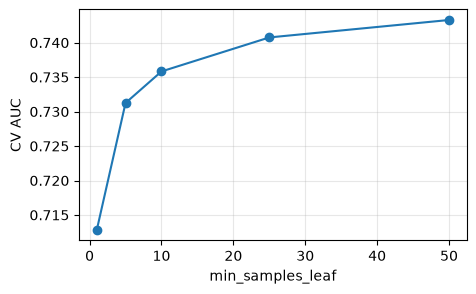

In [7]:
leaves = [1, 5, 10, 25, 50]
scores = [cv_auc(RandomForestClassifier(n_estimators=300, min_samples_leaf=l, random_state=42, n_jobs=-1))
          for l in leaves]
for l, s in zip(leaves, scores):
    print(f"min_samples_leaf={l:>2}: CV AUC {s:.3f}")
plt.figure(figsize=(5, 3)); plt.plot(leaves, scores, marker="o")
plt.xlabel("min_samples_leaf"); plt.ylabel("CV AUC"); plt.grid(alpha=.3); plt.show()

Fully grown trees (leaf size 1) are clearly worst (0.713): each one memorises noise, and even 300 of them do not fully cancel it. AUC keeps climbing with larger leaves, reaching 0.743 at 50 customers per leaf, slightly above the logistic benchmark (0.740). Very smooth trees produce smooth average predictions, closer to the gentle straight-line pattern in this data. On a noisy target, leaf size is a cheap and powerful regulariser; tune it (05.6) rather than leaving the default.